# Steel Plant Energy Forecasting: Next 15-Minute Interval



##  Import libraries and load the data



In [2]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

CLEAN_PATH = Path('cleaned_train.csv')
MODEL_PATH = Path("steel_energy_model.joblib")
TARGET = "next_interval_Usage_kWh"



In [3]:

raw = pd.read_csv('train.csv')
print("Shape:", raw.shape)
raw.head()

Shape: (28031, 12)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,next_interval_Usage_kWh
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,4.00
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,3.24
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,3.31
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,3.82
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load,3.28


## Check and clean the data

In [4]:
required = {"date", "Usage_kWh", TARGET}
missing_columns = required - set(raw.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

df = raw.copy()

# Parse dates from the ORIGINAL text column.
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y %H:%M", errors="coerce")

n_bad = int(df["date"].isna().sum())
print(f"Rows with unparseable dates: {n_bad} of {len(df)}")

# If (almost) everything failed, the format string doesn't match your file.
if n_bad > 0.5 * len(df):
    print("Most dates failed. Example raw values:")
    print(raw["date"].head().tolist())
    print("Adjust the format string above to match them.")

Rows with unparseable dates: 0 of 28031


In [5]:
rows_before = len(df)

df = df.dropna(subset=["date", TARGET])
df = df.sort_values("date").drop_duplicates(subset=["date"]).reset_index(drop=True)

print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning : {len(df)}")
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate timestamps:", int(df["date"].duplicated().sum()))
print("\nTarget summary:")
print(df[TARGET].describe())

Rows before cleaning: 28031
Rows after cleaning : 28031
Date range: 2018-01-01 00:00:00 to 2018-10-19 23:45:00
Total missing cells: 0
Duplicate timestamps: 0

Target summary:
count    28031.000000
mean        27.926530
std         33.921641
min          2.450000
25%          3.130000
50%          4.610000
75%         51.260000
max        153.140000
Name: next_interval_Usage_kWh, dtype: float64


In [6]:
# Save the cleaned dataset (required for the submission).
df.to_csv(CLEAN_PATH, index=False)
print(f"Saved cleaned dataset to: {CLEAN_PATH.resolve()}")
df.head()

Saved cleaned dataset to: C:\Users\Abhishiek\devs-data-divergence\cleaned_train.csv


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,next_interval_Usage_kWh
0,2018-01-01 00:00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load,3.20
1,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,4.00
2,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,3.24
3,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,3.31
4,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,3.82


## Create Features and Target


In [7]:
y = df[TARGET]
print("y shape:", y.shape)
print("Input columns available:", [c for c in df.columns if c != TARGET])

y shape: (28031,)
Input columns available: ['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


##  Time features and cyclical features

In [8]:
def make_features(data):
    """Create predictors using information in the current row only."""
    x = data.drop(columns=[TARGET], errors="ignore").copy()
    dt = pd.to_datetime(x.pop("date"), errors="coerce")

    x["hour"] = dt.dt.hour
    x["minute"] = dt.dt.minute
    x["day_of_week_from_date"] = dt.dt.dayofweek
    x["month"] = dt.dt.month
    x["day_of_year"] = dt.dt.dayofyear

    minute_of_day = x["hour"] * 60 + x["minute"]
    x["hour_sin"] = np.sin(2 * np.pi * minute_of_day / 1440)
    x["hour_cos"] = np.cos(2 * np.pi * minute_of_day / 1440)
    x["year_sin"] = np.sin(2 * np.pi * x["day_of_year"] / 365.25)
    x["year_cos"] = np.cos(2 * np.pi * x["day_of_year"] / 365.25)
    return x

X = make_features(df)
print("Number of features:", X.shape[1])
print("Categorical (text) features:", X.select_dtypes(include=["object", "category"]).columns.tolist())
X.head()

Number of features: 19
Categorical (text) features: ['WeekStatus', 'Day_of_week', 'Load_Type']


C:\Users\Abhishiek\AppData\Local\Temp\ipykernel_41072\3457057634.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Categorical (text) features:", X.select_dtypes(include=["object", "category"]).columns.tolist())


,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,hour,minute,day_of_week_from_date,month,day_of_year,hour_sin,hour_cos,year_sin,year_cos
0,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load,0,0,0,1,1,0.000000,1.000000,0.017202,0.999852
1,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,0,15,0,1,1,0.065403,0.997859,0.017202,0.999852
2,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,0,30,0,1,1,0.130526,0.991445,0.017202,0.999852
3,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,0,45,0,1,1,0.195090,0.980785,0.017202,0.999852
4,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,1,0,0,1,1,0.258819,0.965926,0.017202,0.999852


## Train-Test-Split

In [9]:
split_at = int(len(df) * 0.80)
X_train, X_valid = X.iloc[:split_at], X.iloc[split_at:]
y_train, y_valid = y.iloc[:split_at], y.iloc[split_at:]

print(f"Training rows  : {len(X_train)}")
print(f"Validation rows: {len(X_valid)}")
print("Training ends  :", df["date"].iloc[split_at - 1])
print("Validation starts:", df["date"].iloc[split_at])

Training rows  : 22424
Validation rows: 5607
Training ends  : 2018-08-22 13:45:00
Validation starts: 2018-08-22 14:00:00


## Baseline

In [10]:
def report_scores(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f"{name} MAE : {mae:.4f} kWh")
    print(f"{name} RMSE: {rmse:.4f} kWh")
    return mae, rmse

baseline_predictions = df["Usage_kWh"].iloc[split_at:].to_numpy()
baseline_mae, baseline_rmse = report_scores("Persistence baseline", y_valid, baseline_predictions)

Persistence baseline MAE : 5.2798 kWh
Persistence baseline RMSE: 11.9469 kWh


##  Build and train the model pipeline

In [11]:
def build_model(X):
    categorical = X.select_dtypes(include=["object", "category"]).columns.tolist()
    numeric = [col for col in X.columns if col not in categorical]

    preprocessing = ColumnTransformer(
        transformers=[
            ("numeric", SimpleImputer(strategy="median"), numeric),
            (
                "categorical",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categorical,
            ),
        ],
        remainder="drop",
    )

    regressor = HistGradientBoostingRegressor(
        max_iter=120,
        learning_rate=0.08,
        max_leaf_nodes=25,
        l2_regularization=1.0,
        random_state=42,
    )
    return Pipeline(steps=[("preprocessing", preprocessing), ("regressor", regressor)])

model = build_model(X_train)
model.fit(X_train, y_train)
print("Model trained.")

C:\Users\Abhishiek\AppData\Local\Temp\ipykernel_41072\2070750251.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X.select_dtypes(include=["object", "category"]).columns.tolist()


Model trained.


##  Evaluate with MAE and RMSE

In [12]:
predictions = model.predict(X_valid)
model_mae, model_rmse = report_scores("HistGradientBoosting", y_valid, predictions)

results = pd.DataFrame(
    {"MAE (kWh)": [baseline_mae, model_mae], "RMSE (kWh)": [baseline_rmse, model_rmse]},
    index=["Persistence baseline", "HistGradientBoosting"],
)
results

HistGradientBoosting MAE : 3.9656 kWh
HistGradientBoosting RMSE: 8.7345 kWh


,MAE (kWh),RMSE (kWh)
Persistence baseline,5.279809,11.946913
HistGradientBoosting,3.965596,8.734499


## Compare predictions with actual values

In [13]:
comparison = pd.DataFrame(
    {
        "date": df["date"].iloc[split_at:].to_numpy(),
        "actual": y_valid.to_numpy(),
        "predicted": predictions,
    }
)
comparison["error"] = comparison["predicted"] - comparison["actual"]
comparison.head(10)

,date,actual,predicted,error
0,2018-08-22 14:00:00,68.76,55.529294,-13.230706
1,2018-08-22 14:15:00,60.73,64.269043,3.539043
2,2018-08-22 14:30:00,60.70,59.551457,-1.148543
3,2018-08-22 14:45:00,46.22,59.099915,12.879915
4,2018-08-22 15:00:00,55.66,50.803066,-4.856934
5,2018-08-22 15:15:00,47.59,57.229566,9.639566
6,2018-08-22 15:30:00,61.60,52.281662,-9.318338
7,2018-08-22 15:45:00,53.28,60.897609,7.617609
8,2018-08-22 16:00:00,56.05,56.212721,0.162721
9,2018-08-22 16:15:00,58.75,57.788545,-0.961455


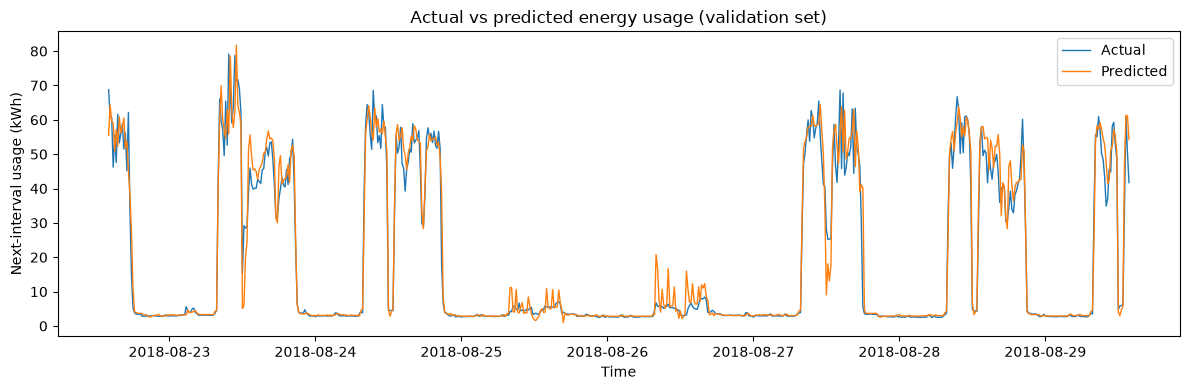

In [14]:

window = comparison.head(7 * 96)

plt.figure(figsize=(12, 4))
plt.plot(window["date"], window["actual"], label="Actual", linewidth=1)
plt.plot(window["date"], window["predicted"], label="Predicted", linewidth=1)
plt.xlabel("Time")
plt.ylabel("Next-interval usage (kWh)")
plt.title("Actual vs predicted energy usage (validation set)")
plt.legend()
plt.tight_layout()
plt.show()

##  Train the final model and save it



In [15]:
final_model = build_model(X)
final_model.fit(X, y)
joblib.dump(final_model, MODEL_PATH)
print(f"Saved final trained model to: {MODEL_PATH.resolve()}")

C:\Users\Abhishiek\AppData\Local\Temp\ipykernel_41072\2070750251.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X.select_dtypes(include=["object", "category"]).columns.tolist()


Saved final trained model to: C:\Users\Abhishiek\devs-data-divergence\steel_energy_model.joblib


### Using the saved model for later

In [16]:
loaded = joblib.load(MODEL_PATH)
new_rows = df.drop(columns=[TARGET]).tail(1)
print(
    "Predicted next-interval usage (kWh):", loaded.predict(make_features(new_rows))[0]
)


Predicted next-interval usage (kWh): 61.87836754756924
